# 4.4 · 深度学习模型：MLP · LSTM · ALSTM · Transformer · GNN

> 深度学习能从原始量价序列中**自动学习复杂的非线性和时序模式**，是量化的前沿方向。
> 本节理解神经网络的基本结构，跑一个前馈网络（MLP），并了解 LSTM、注意力、Transformer、GNN 的原理。

## 一、神经网络基础

- **神经元**：对输入做加权求和，再过一个**激活函数**（如 ReLU，引入非线性）；
- **隐藏层**：多层神经元堆叠，层数越多表达能力越强；
- **前馈网络（MLP）**：信息从输入层单向流向输出层；
- **训练**：通过**反向传播**计算损失对每个权重的梯度，用梯度下降更新权重，最小化预测误差。

$$h = \mathrm{ReLU}(W_1 x + b_1), \quad \hat{y} = W_2 h + b_2$$

> 对截面因子做 MLP，就是 Qlib 的 **DNN 模型**：输入因子向量，输出预测，自动学因子的非线性组合。

## 二、前馈网络（MLP）实测

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from model_lab.data import build_panel, split_by_date, predict_ic
from model_lab.linear import rank_label
from model_lab.deep import fit_mlp, TORCH_LSTM
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close','$volume','$mkt_cap_ard','$pe_ttm','$pb_lf'], freq='day')
close = F['$close'].unstack('instrument')
df = build_panel(close, F['$volume'].unstack('instrument'),
                 F['$mkt_cap_ard'].unstack('instrument'),
                 F['$pe_ttm'].unstack('instrument'),
                 F['$pb_lf'].unstack('instrument'), 1)
tr, va, te = split_by_date(df, '2022-12-31', '2023-12-31')
feat = [c for c in df.columns if c != 'label']
tr_r = rank_label(tr)
mlp = fit_mlp(tr_r, feat, label='y_rank')
pred = pd.Series(mlp.predict(te[feat]), index=te.index)
ic = predict_ic(pred, te['label'])
print('MLP 迭代次数 %d' % mlp.n_iter_)
print('测试集 IC %.4f  IR %.4f  胜率 %.3f' % (ic.mean(), ic.mean()/ic.std(), (ic>0).mean()))

[2416:MainThread](2026-10-30 01:27:19,030) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[2416:MainThread](2026-10-30 01:27:20,491) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[2416:MainThread](2026-10-30 01:27:20,492) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


MLP 迭代次数 14
测试集 IC 0.0292  IR 0.1644  胜率 0.540


## 三、序列模型：LSTM 与 GRU

MLP 把因子当作独立的输入，没有"时间顺序"概念。**循环神经网络（RNN）**专门处理序列：
- 网络在每个时间步有一个**隐藏状态**，像"记忆"，把过去的信息传递到当前；
- **LSTM（长短期记忆）/ GRU**：通过"门控"机制（输入门、遗忘门、输出门）选择性记忆和遗忘，解决了普通 RNN 难以学习长程依赖的问题。

量化用法：输入一只股票过去 N 天的量价序列（开高低收、量等），LSTM 输出未来收益预测。

## 四、注意力机制：ALSTM 与 Transformer

- **注意力（Attention）**：让模型在预测时"关注"序列中更重要的时间步（加权聚合，权重由学习得到）；
- **ALSTM**：在 LSTM 上叠加注意力，是 Qlib 中表现稳健的序列模型；
- **Transformer**：完全基于**自注意力（Self-Attention）**，并行计算任意两个时间步的关系，捕捉长程依赖，是当下主流。

> 输入可以是"过去 60 个交易日的量价特征"，模型自动学习哪些天的形态对未来最重要。

## 五、图神经网络（GNN）

股票之间存在关系（同行业、供应链、股权关联）。**图神经网络（GNN）**：
- 把股票作为节点、关系作为边；
- 每个节点通过聚合"邻居"的信息更新自己的表示；
- 学习关系驱动的因子（如龙头股带动、产业链传导）。

代表：Qlib 的 GATs（图注意力网络）。

## 六、PyTorch 序列模型框架（安装 torch 后可跑）

In [2]:
# 打印 LSTM / ALSTM 的 PyTorch 框架代码
print(TORCH_LSTM)


import torch, torch.nn as nn

class LSTMModel(nn.Module):
    """输入 [批次, 时间步, 特征数] 的量价序列，输出每只股票的预测。"""
    def __init__(self, n_feat, hidden=64, n_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, n_layers,
                            batch_first=True, dropout=0.1)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)

class ALSTMModel(LSTMModel):
    """在 LSTM 输出上加注意力（Qlib 常用 ALSTM）。"""
    def __init__(self, n_feat, hidden=64, n_layers=2):
        super().__init__(n_feat, hidden, n_layers)
        self.attn = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        w = torch.softmax(self.attn(out), dim=1)
        ctx = (w * out).sum(dim=1)
        return self.head(ctx).squeeze(-1)



## 七、深度学习的挑战

1. **过拟合**：参数多、金融数据噪声大，极易记住噪声——需要正则（dropout、weight decay）、交叉验证；
2. **数据量**：深度模型需要大量样本，日频 A 股样本相对有限（分钟频/截面数据可扩充）；
3. **调参敏感**：网络结构、学习率、批次都影响结果，训练不稳定；
4. **可解释性弱**：黑盒，机构常要求因子可解释、可归因；
5. **算力**：序列模型训练成本高。

> 实践中，**LightGBM 常常是性价比最高的选择**，深度模型在数据和算力充足时才稳定占优。

## 八、全模型对比

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[16]	valid_0's l2: 0.0832743


              IC      IR
等权        0.0397  0.1462
Ridge     0.0280  0.1379
LightGBM  0.0315  0.1733
MLP       0.0292  0.1644


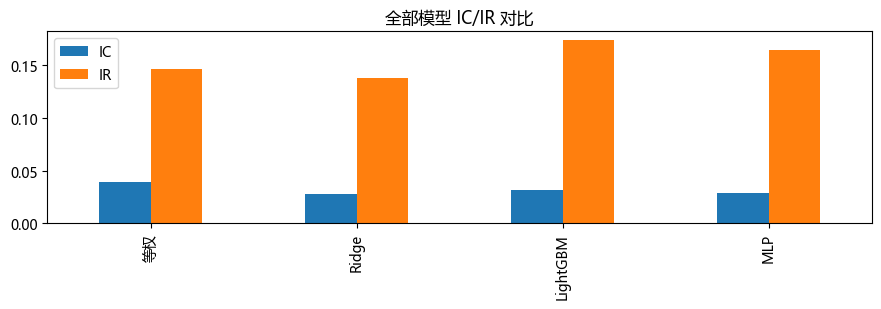

In [3]:
from model_lab.linear import fit_linear
from model_lab.tree import fit_lgb
equal = te[feat].mean(axis=1); ic_eq = predict_ic(equal, te['label'])
ridge = fit_linear(tr, feat, 'ridge', 1.0, True); ic_rd = predict_ic(pd.Series(ridge.predict(te[feat]),index=te.index), te['label'])
va_r = rank_label(va); lgbm = fit_lgb(tr_r, va_r, feat, 'y_rank'); ic_lg = predict_ic(pd.Series(lgbm.predict(te[feat]),index=te.index), te['label'])
rows = {'等权':ic_eq,'Ridge':ic_rd,'LightGBM':ic_lg,'MLP':ic}
cmp = pd.DataFrame({k:[v.mean(), v.mean()/v.std()] for k,v in rows.items()},
                   index=['IC','IR']).T
print(cmp.round(4))
cmp.plot(kind='bar', figsize=(9,3.2)); plt.title('全部模型 IC/IR 对比'); plt.tight_layout(); plt.show()

## 九、小结与面试要点

- 神经网络 = 神经元 + 激活函数 + 多层；反向传播 + 梯度下降训练。
- MLP 学因子非线性组合；LSTM/GRU 处理时序记忆；ALSTM/Transformer 用注意力；GNN 学股票关系。
- 深度模型挑战：过拟合、数据量、调参、可解释性、算力；LightGBM 常是性价比之王。

**面试高频：**
- LSTM 为什么比普通 RNN 好？（答：门控机制解决长程依赖和梯度消失）
- 注意力机制是什么？（答：对重要时间步/特征加权聚合，权重由学习得到）
- 深度学习在量化里为什么不总能赢 LightGBM？（答：金融噪声大、样本有限、易过拟合、可解释性差）
- 怎么缓解深度模型过拟合？（答：dropout、weight decay、early stop、交叉验证、扩充样本）

## 动手练习
1. 改变 MLP 隐藏层结构，观察 IC；
2. 若已安装 torch，用 TORCH_LSTM 框架在量价序列上训练；
3. 思考：为什么 Transformer 能并行而 LSTM 不能？

---
下一节 **4.5 滚动训练、模型评估与集成、防过拟合体系**。